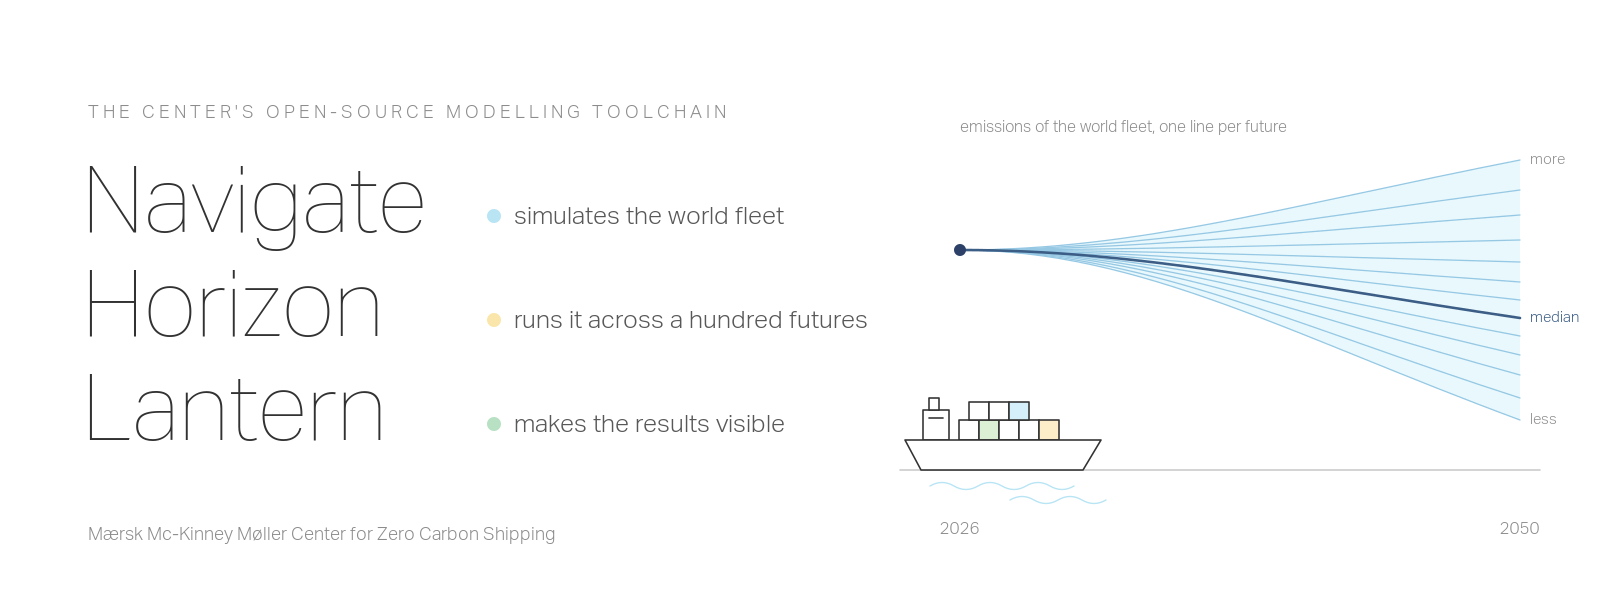

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/leadership-demo/demo/leadership/leadership_demo.ipynb)

> **For the presenter.** Open the notebook in Colab and run the **Setup** cell about five minutes before the
> meeting. In the meeting, run the cells one by one (Shift+Enter) as you talk. The notebook opens with the results
> of an earlier run, so every chart is there before a cell runs.
>
> *Navigate is a research model. The three scenarios test it across degrees of regulation; they are not the
> Center's view of likely futures, and their results are illustrations, not forecasts or advice.*

## One toolchain, from a question to a range of answers

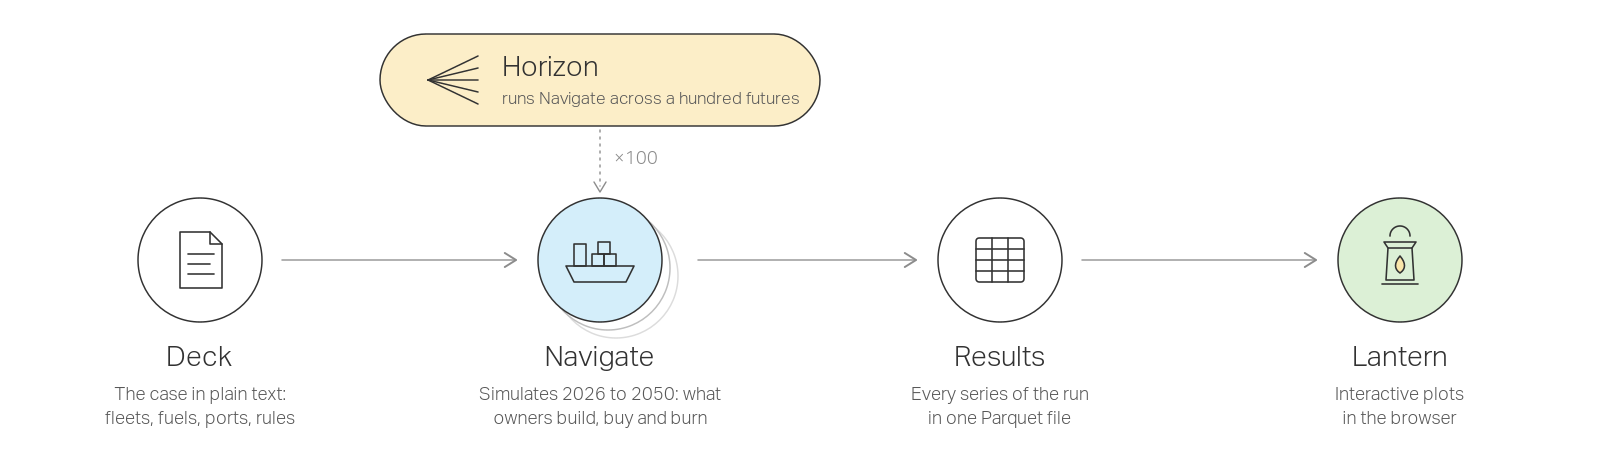

- **Navigate** simulates the fleet year by year: which ships owners build, retrofit and scrap, which fuels they
  burn, and which fuel plants producers build, each on what they expect prices and rules to bring.
- **Horizon** runs the same case across many futures at once, so every result comes with its range and its drivers.
- **Lantern** turns a run, or a whole study, into interactive plots in the browser.

All three, and the data library behind the case, are open source.

## Setup · run before the meeting

Installs the three tools in this Colab session and loads the case: about two minutes.

In [1]:
# @title Setup: install Navigate, Horizon and Lantern, and load the case { display-mode: "form" }
ROOT = "/content"
# ROOT = "/tmp/leadership_demo"  # running locally: any folder of your own, without spaces in its path

# the demo's branch holds its study and the results bundled with it; Horizon and Lantern are pinned to the
# commits the demo was made with, so a later change to either cannot break it
BRANCH = "leadership-demo"
HORIZON = "23f7df9dbaa17546d9336be062111cc836fa4cfb"
LANTERN = "28ffcb25ca9a98ec1c89c42de401150f1dac862a"

import os
import shutil
import subprocess
import sys
from pathlib import Path

repository = Path(ROOT, "navigate-zcs")
if not repository.exists():  # a second run reuses the clone
    subprocess.run(["git", "clone", "-q", "--depth", "1", "-b", BRANCH,
                    "https://github.com/zerocarbonshipping/navigate-zcs", str(repository)], check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check", str(repository),
                f"git+https://github.com/zerocarbonshipping/horizon-zcs@{HORIZON}",
                f"git+https://github.com/zerocarbonshipping/lantern-zcs@{LANTERN}"], check=True)

# the tools' commands next to this Python, and Navigate's data library from the clone
os.environ["PATH"] = f"{Path(sys.executable).parent}{os.pathsep}{os.environ['PATH']}"
os.environ["ASSUMPTIONS_DATA_DIR"] = str(repository / "assumptions")

# the case: notebook 2's world fleet, with the demo's study, plots and bundled results on top
case = Path(ROOT, "world_fleet")
shutil.rmtree(case, ignore_errors=True)
shutil.copytree(repository / "docs" / "notebooks" / "notebook_2" / "global_case", case)
shutil.copytree(repository / "demo" / "leadership" / "overlay", case, dirs_exist_ok=True)
shutil.copytree(repository / "demo" / "leadership" / "results", case / "bundled")
os.chdir(case)

# the demo's cards and charts
sys.path.insert(0, str(repository / "demo" / "leadership"))
import showcase

showcase.ready()

---

## The question

### What will the world fleet burn to 2050, and how much does regulation change it?

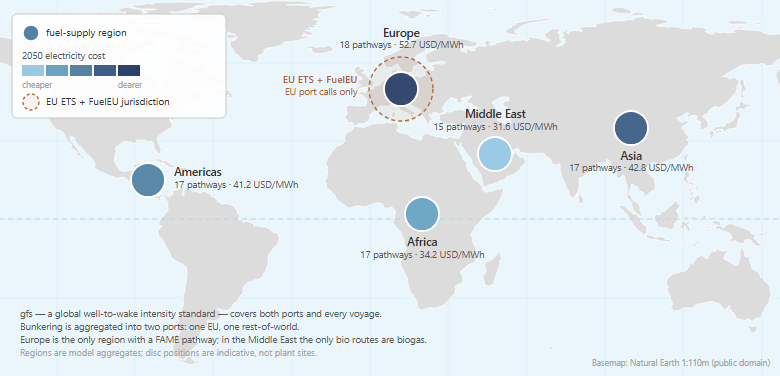

The case is the Center's reference scenario: the whole international fleet in 23 ship classes, and fuels made in
five supply regions, all from Navigate's open data library. Three scenarios differ only in regulation:

| Scenario | Regulation |
|---|---|
| **No regulation** | none: fuel chosen on cost alone |
| **Mid regulation** | EU ETS + FuelEU + a moderate global fuel standard |
| **Strong regulation** | EU ETS + FuelEU + a strict global fuel standard |

---

## 1 · Navigate: simulate the world fleet to 2050

Each scenario is one deck and one command. Navigate steps through time, and at each step owners and fuel producers
decide what to build and burn. On a coarse grid of eight time steps a scenario solves in about a minute; mid
regulation solves live, the other two were solved before the meeting.

In [2]:
# @title Solve the scenarios { display-mode: "form" }
LIVE = "mid regulation"  # @param ["mid regulation", "all three", "none: bundled results"]
# "all three" solves them side by side, two to three minutes on Colab
showcase.solve(LIVE)

In [3]:
# @title What Navigate found { display-mode: "form" }
showcase.scorecards()

In [4]:
# @title The fuel mix, 2026 to 2050 { display-mode: "form" }
showcase.fuel_mix()

In [5]:
# @title What the rules collect { display-mode: "form" }
showcase.collected()

The same results as Lantern draws them, straight from the results files: hover to read a value, drag to zoom.

In [6]:
# Lantern draws plots of the results files as web pages; the notebook shows two of them
runs = "basecase_no_regulation,basecase_mid_regulation,basecase_strong_regulation"
!lantern parquets --scale 0.8 --plot "headline_emissions[{runs}]" --plot "headline_expenses_total[{runs}]"

pages = runs.replace(",", "+")
showcase.show(f"plots/headline_emissions/{pages}.html", f"plots/headline_expenses_total/{pages}.html",
              titles=("Well-to-wake emissions", "What the ships paid, per tonne-km"))

Plots from /content/world_fleet/plots.yaml


Loaded basecase_mid_regulation: 1 run(s), 55 of 61 plots with data


Loaded basecase_no_regulation: 1 run(s), 51 of 61 plots with data


Loaded basecase_strong_regulation: 1 run(s), 55 of 61 plots with data


Plotting:   0%|                                        | 0/2 [00:00<?, ?plot/s]

Plotting:  50%|████████████████                | 1/2 [00:00<00:00,  8.90plot/s]

Plotting: 100%|████████████████████████████████| 2/2 [00:00<00:00, 12.97plot/s]
Wrote 2 plots to plots
plots/headline_emissions/basecase_no_regulation+basecase_mid_regulation+basecase_strong_regulation.html
plots/headline_expenses_total/basecase_no_regulation+basecase_mid_regulation+basecase_strong_regulation.html


---

## 2 · Horizon: one future is a guess, so run a hundred

A single run answers *what if* for one set of assumptions. Horizon takes the mid regulation scenario, draws each of
eight assumptions from a range, and runs Navigate once per draw: a hundred futures, solved in parallel. The study is
one short file, `demo.hor`.

A hundred runs take about half an hour on a workstation, so they ran before the meeting. Tick `RUN_STUDY_LIVE` to
run a study of six futures here instead, in about three minutes.

In [7]:
# @title Load the study { display-mode: "form" }
RUN_STUDY_LIVE = False  # @param {type:"boolean"}
if RUN_STUDY_LIVE:
    !horizon run demo.hor --samples 6
    !horizon collect demo.hor
else:
    showcase.use_bundled_study()

In [8]:
# @title How often the fleet gets there { display-mode: "form" }
CUT = 50  # @param {type:"slider", min:10, max:90, step:5}
# the cut in well-to-wake emissions from 2026 to 2050, in percent: move it and run the cell again
showcase.target(CUT)

In [9]:
# @title What moves the result { display-mode: "form" }
showcase.drivers()

---

## 3 · Lantern: every plot, in the browser

Lantern's viewer holds every plot it can draw of the three scenarios and the hundred futures: fuels, fleets, ports,
fuel plants and regulation. It opens in a new tab.

In [ ]:
# @title Open Lantern { display-mode: "form" }
showcase.open_lantern("parquets", "study/demo.parquet")

---

## What this gives us

- **Fast answers.** A new question is a new deck or a new lever; the world fleet solves in about a minute on the
  coarse grid.
- **Ranges, not single numbers.** Horizon puts a band on every result and shows which assumptions move it.
- **Open and reproducible.** The model, its data library and the tools are open source, and this notebook runs in
  any browser.

[Navigate](https://github.com/zerocarbonshipping/navigate-zcs) ·
[Horizon](https://github.com/zerocarbonshipping/horizon-zcs) ·
[Lantern](https://github.com/zerocarbonshipping/lantern-zcs) ·
[Documentation](https://zerocarbonshipping.github.io/navigate-zcs/)